# Fase 2 · Modelado

**Riesgo de impago de tarjetas de crédito.** Proyecto Final de Ciencia de Datos (Sección A), UFM.
Responsable de esta fase: George Albadr.

Este notebook parte de lo que dejó la fase 1 (`01_framing_datos_eda.ipynb`) y responde una sola
pregunta: **¿qué modelo convierte mejor los datos de un cliente en una probabilidad de impago que el
banco pueda usar para decidir?**

Reglas que se cumplen en todo el notebook:

1. **Solo se usa `train.csv`.** La prueba (`test.csv`) no se abre aquí. Se abre una vez, en el notebook 03.
2. **Todo se mide con 5 simulacros** (validación cruzada estratificada). Un solo simulacro engaña.
3. **La métrica es el costo promedio por cliente**, con los umbrales 0.12 y 0.35 de la fase 1. La vara
   es 0.853: lo que cuesta revisar a todos sin modelo.
4. **Todo lo que aprende de los datos va dentro de un `Pipeline`**, para que cada simulacro aprenda
   solo con sus datos de estudio.

Contenido: (1) preparación, (2) logística, (3) regularización, (4) pesos por clase y calibración,
(5) árbol, (6) bosque y boosting, (7) comparación, (8) con y sin sexo y estado civil, (9) modelo
elegido, (10) qué queda para la evaluación.

In [1]:
import sys
import warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.tree import export_text

from src import costos, datos, modelado, variables

warnings.filterwarnings("ignore", category=FutureWarning)
DIR_FIG = RAIZ / "figures"
DIR_FIG.mkdir(exist_ok=True)

# Misma paleta y estilo que el notebook 01.
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"{nombre}.png")

## 1. Preparación

### 1.1 Datos, particiones y la vara

Se carga el entrenamiento limpio de la fase 1 y se agregan las cuatro **variables candidatas** que
salieron del EDA (`src/variables.py`):

| Variable | De qué hallazgo viene |
|---|---|
| `MESES_ATRASO` | El historial de pagos domina la señal (EDA 5.2). Cuenta meses con atraso; no suma códigos |
| `ATRASO_ULTIMO` | Un atraso en septiembre sube el impago de ~12 % a ~34 % (EDA 5.2) |
| `USO_LINEA` | Más uso de la línea, más impago, con forma de U (EDA 5.3) |
| `INACTIVO` | Las cuentas sin movimiento impagan ~37 % (EDA 5.5) |

Ninguna usa el objetivo ni aprende nada del conjunto (son cuentas fila por fila), así que calcularlas
antes de partir los datos no es trampa.

In [2]:
train = variables.agregar_candidatas(datos.cargar_train())
y = train[datos.OBJETIVO]
X = train.drop(columns=datos.OBJETIVO)

BASE = [c for c in X.columns if c not in variables.CANDIDATAS]      # las 23 columnas originales
TODAS = list(X.columns)                                              # originales + candidatas
SIN_PROTEGIDAS = [c for c in TODAS if c not in variables.PROTEGIDAS]  # sin SEX ni MARRIAGE

t1, t2 = costos.umbrales_teoricos()       # 0.12 y 0.35: salen de los costos, no de los datos
cv = modelado.particiones()               # 5 simulacros, barajados y estratificados, semilla fija
VARA = costos.costo_politica_trivial(y, 1)  # revisar a todos, sin modelo

print(f"Entrenamiento: {len(X):,} clientes, {X.shape[1]} columnas ({len(BASE)} originales + {len(variables.CANDIDATAS)} candidatas)")
print(f"Tasa de impago: {y.mean():.3f}")
print(f"Umbrales: t1 = {t1:.2f}, t2 = {t2:.2f}")
print(f"Vara (revisar a todos): {VARA:.3f}")
print("Impago en cada simulacro:", [round(float(y.iloc[te].mean()), 3) for _, te in cv.split(X, y)])

Entrenamiento: 24,000 clientes, 27 columnas (23 originales + 4 candidatas)
Tasa de impago: 0.221
Umbrales: t1 = 0.12, t2 = 0.35
Vara (revisar a todos): 0.853
Impago en cada simulacro: [0.221, 0.221, 0.221, 0.221, 0.221]


### 1.2 Cómo se mide cada modelo

`simular` hace lo mismo con todos los modelos: en cada una de las 5 rondas entrena con cuatro grupos
y predice la probabilidad de impago del quinto. Al final cada cliente tiene una probabilidad que
salió de un modelo **que no lo vio**. Con esas probabilidades se calcula:

- **Costo por cliente** en cada ronda y su promedio (la métrica que decide).
- **AUC:** si el modelo ordena bien (un impago al azar contra un pago al azar).
- **AP** (área bajo la curva precisión-recall): lo mismo, pero mirando la clase de impago.
- **Probabilidad media:** si el modelo dice la verdad en promedio, debe ser cercana a 0.221.

In [3]:
resultados = {}   # nombre -> fila de la tabla
probas = {}       # nombre -> probabilidades fuera de muestra (una por cliente)


def simular(nombre, modelo, columnas):
    # Probabilidad de impago de cada cliente, predicha por un modelo que no lo vio.
    p = cross_val_predict(modelo, X[columnas], y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    rondas = modelado.costo_por_ronda(y, p, cv)
    probas[nombre] = p
    resultados[nombre] = {
        **{f"ronda {i + 1}": c for i, c in enumerate(rondas)},
        "costo": rondas.mean(),
        "AUC": roc_auc_score(y, p),
        "AP": average_precision_score(y, p),
        "prob. media": p.mean(),
    }
    return p


def tabla(nombres):
    return pd.DataFrame({n: resultados[n] for n in nombres}).T

## 2. Línea base: regresión logística

**Por qué empezar aquí.** Es el modelo de la propuesta y el más fácil de explicar: una suma con pesos
pasada por una curva S. Además se entrena minimizando el castigo por equivocarse con confianza
(log-loss), así que sus probabilidades tienden a decir la verdad, y nuestros umbrales necesitan eso.

**Preparación que necesita** (`modelado.logistica`), toda decidida en el EDA:

- Montos: `sign(x)·log1p(|x|)` y escala estándar, por las colas largas (EDA 5.6).
- `EDUCATION`, `SEX`, `MARRIAGE`: una columna por categoría, porque sus códigos no son cantidades.
- Regularización L2: los seis meses de facturas casi repiten la misma información (EDA 5.7).

**Lo que la fase 1 dejó abierto** y se decide aquí con los 5 simulacros:

1. ¿Las `PAY_*` entran como **número** o como **categoría**?
2. ¿Las variables candidatas bajan el costo?

In [4]:
simular("logística · PAY número", modelado.logistica(BASE, pay_categorica=False), BASE)
simular("logística · PAY categoría", modelado.logistica(BASE, pay_categorica=True), BASE)
simular("logística · PAY número + candidatas", modelado.logistica(TODAS, pay_categorica=False), TODAS)
simular("logística · PAY categoría + candidatas", modelado.logistica(TODAS, pay_categorica=True), TODAS)

tabla(["logística · PAY número", "logística · PAY categoría",
       "logística · PAY número + candidatas", "logística · PAY categoría + candidatas"])

,ronda 1,ronda 2,ronda 3,ronda 4,ronda 5,costo,AUC,AP,prob. media
logística · PAY número,0.7678,0.7528,0.7597,0.7583,0.7631,0.7603,0.7496,0.5068,0.2212
logística · PAY categoría,0.7321,0.7215,0.7261,0.7260,0.7307,0.7273,0.7765,0.5496,0.2212
logística · PAY número + candidatas,0.7542,0.7346,0.7408,0.7348,0.7423,0.7413,0.7616,0.5115,0.2212
logística · PAY categoría + candidatas,0.7263,0.7210,0.7279,0.7216,0.7279,0.7249,0.7801,0.5502,0.2212


**Lectura.**

- **`PAY_*` como categoría baja el costo de 0.760 a 0.727**, y gana en las cinco rondas. Tiene
  sentido con el EDA: los códigos -2, -1 y 0 tienen tasas de impago parecidas y el salto está entre 0
  y 1 o más. Como número, la logística está obligada a suponer que cada paso del código suma lo mismo;
  como categoría, cada código recibe su propio peso.
- **Las candidatas ayudan mucho cuando `PAY_*` es número** (0.760 a 0.741) **y casi nada cuando es
  categoría** (0.727 a 0.725): las dos cosas le dan al modelo la misma información por caminos
  distintos.

**Decisión.** `PAY_*` como categoría, con las candidatas. La mejora de las candidatas es de 0.002,
menor que lo que se mueve el costo entre rondas, así que no se afirma que "sirven": se dejan porque
no estorban, la regularización las controla y a los modelos de árboles les ahorran trabajo.

Las cuatro versiones tienen probabilidad media 0.221, igual a la tasa real: sin pesos por clase, la
logística dice la verdad en promedio.

## 3. Regularización: elegir la perilla `C`

`C` controla cuánto se castigan los pesos grandes. **`C` pequeño = más regularización** (pesos más
chicos, modelo más simple). Se prueban seis valores, cada uno con sus cinco simulacros, y se elige
por costo, no por exactitud.

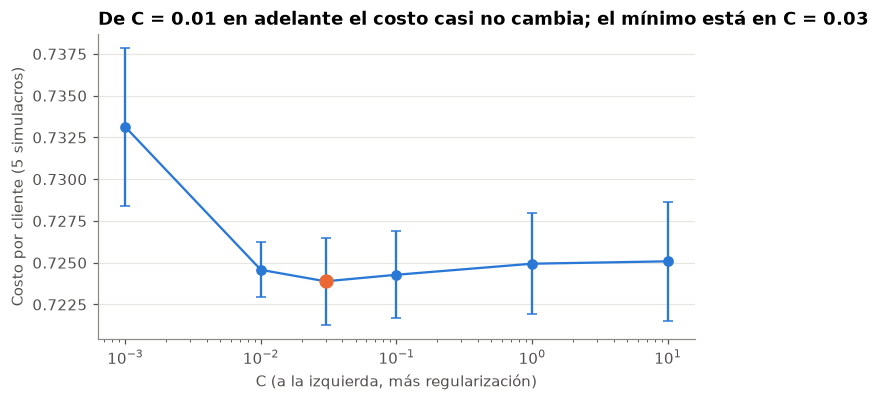

Mejor C: 0.03


,C,costo,desviación entre rondas
0,0.0010,0.7331,0.0047
1,0.0100,0.7246,0.0016
2,0.0300,0.7239,0.0026
3,0.1000,0.7243,0.0026
4,1.0000,0.7249,0.0030
5,10.0000,0.7251,0.0036


In [5]:
perillas_C = {"logisticregression__C": [0.001, 0.01, 0.03, 0.1, 1, 10]}
busqueda_C = GridSearchCV(modelado.logistica(TODAS), perillas_C, cv=cv,
                          scoring=modelado.PUNTAJE_COSTO, n_jobs=-1).fit(X[TODAS], y)

res_C = pd.DataFrame(busqueda_C.cv_results_)
curva_C = pd.DataFrame({
    "C": res_C["param_logisticregression__C"].astype(float),
    "costo": -res_C["mean_test_score"],          # el puntaje es el costo con signo negativo
    "desviación entre rondas": res_C["std_test_score"],
})
MEJOR_C = busqueda_C.best_params_["logisticregression__C"]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(curva_C["C"], curva_C["costo"], yerr=curva_C["desviación entre rondas"],
            color=AZUL, marker="o", capsize=3)
ax.scatter([MEJOR_C], [curva_C.loc[curva_C["C"] == MEJOR_C, "costo"].iloc[0]], color=NARANJA, zorder=3, s=70)
ax.set_xscale("log")
ax.set_xlabel("C (a la izquierda, más regularización)")
ax.set_ylabel("Costo por cliente (5 simulacros)")
ax.set_title(f"De C = 0.01 en adelante el costo casi no cambia; el mínimo está en C = {MEJOR_C}")
guardar(fig, "f9_regularizacion_C")
plt.show()

print("Mejor C:", MEJOR_C)
curva_C

**Lectura.** Con muy poca regularización o con mucha (C de 0.01 a 10) el costo se mueve entre 0.7239
y 0.7251: la diferencia es menor que la desviación entre rondas. Solo `C = 0.001` es claramente peor
(0.733): ahí la regularización aplasta los pesos y el modelo deja de usar señal real.

**Decisión.** `C = 0.03`, el mínimo. No es un hallazgo fuerte: cualquier valor de 0.01 en adelante
daría casi lo mismo. Lo que sí se concluye es que **el modelo no es sensible a esta perilla**, y eso
es buena noticia para usarlo.

## 4. Pesos por clase y calibración

El EDA dejó escrito "probar pesos por clase antes que remuestreo", y Milton advirtió: **las
probabilidades hay que calibrarlas antes de aplicarles los umbrales**. Aquí se ve por qué.

Los umbrales 0.12 y 0.35 salen de los costos y suponen que cuando el modelo dice 0.30, cerca del 30 %
de esos clientes impaga. `class_weight="balanced"` le dice al modelo que cada impago pesa como ~3.5
clientes que pagan. El modelo ordena igual de bien, pero sus probabilidades se inflan.

Se comparan tres versiones de la misma logística:

1. Sin pesos.
2. Con pesos por clase.
3. Con pesos por clase y **calibrada** después (regresión isotónica, aprendida dentro de cada ronda).

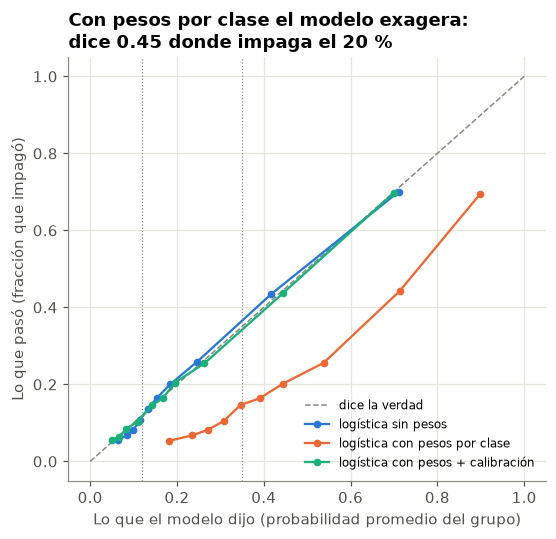

,ronda 1,ronda 2,ronda 3,ronda 4,ronda 5,costo,AUC,AP,prob. media
logística sin pesos,0.7243,0.7222,0.7258,0.7199,0.7273,0.7239,0.7805,0.5490,0.2212
logística con pesos por clase,0.8645,0.8720,0.8656,0.8684,0.8714,0.8684,0.7812,0.5469,0.4325
logística con pesos + calibración,0.7294,0.7265,0.7196,0.7172,0.7214,0.7228,0.7807,0.5464,0.2222


In [6]:
logit_C = dict(C=MEJOR_C)
simular("logística sin pesos", modelado.logistica(TODAS, **logit_C), TODAS)
simular("logística con pesos por clase", modelado.logistica(TODAS, class_weight="balanced", **logit_C), TODAS)
simular("logística con pesos + calibración",
        CalibratedClassifierCV(modelado.logistica(TODAS, class_weight="balanced", **logit_C),
                               method="isotonic", cv=5), TODAS)

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="dice la verdad")
for nombre, color in [("logística sin pesos", AZUL), ("logística con pesos por clase", NARANJA),
                      ("logística con pesos + calibración", AQUA)]:
    # 10 grupos de igual tamaño: lo que el modelo dijo en promedio contra lo que pasó.
    real, dicho = calibration_curve(y, probas[nombre], n_bins=10, strategy="quantile")
    ax.plot(dicho, real, marker="o", ms=4, color=color, label=nombre)
ax.axvline(t1, color=GRIS, lw=0.8, ls=":")
ax.axvline(t2, color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("Lo que el modelo dijo (probabilidad promedio del grupo)")
ax.set_ylabel("Lo que pasó (fracción que impagó)")
ax.set_title("Con pesos por clase el modelo exagera:\ndice 0.45 donde impaga el 20 %")
ax.grid(axis="x")
ax.legend(frameon=False, fontsize=8)
guardar(fig, "f10_calibracion")
plt.show()

tabla(["logística sin pesos", "logística con pesos por clase", "logística con pesos + calibración"])

**Lectura.**

- Con pesos por clase la probabilidad media sube de 0.22 a 0.43. El modelo **ordena igual** (AUC 0.781
  en los tres), pero ya no dice la verdad.
- Aplicarle los umbrales 0.12 y 0.35 a esas probabilidades infladas cuesta **0.868: peor que no tener
  modelo** (0.853). Casi nadie queda debajo de 0.12, así que casi todos van a revisión o reducción.
- Calibrando después, el costo vuelve a 0.723, igual que la logística sin pesos (0.724).

**Decisión.** **Sin pesos por clase.** En este problema el desbalance ya está resuelto en otra parte:
el costo 5 a 1 vive en los umbrales, no en el entrenamiento. Poner pesos y después calibrar da el
mismo resultado con dos pasos más que explicar y mantener.

Esto contesta el pendiente de la fase 1 ("calibrar antes de aplicar los umbrales"): se verificó, y
la logística sin pesos ya está calibrada en la zona donde están los umbrales (línea azul sobre la
diagonal).

## 5. Árbol de decisión

**Por qué probarlo.** La logística supone que una suma suave separa a los clientes. El EDA encontró
cosas que no son una suma: el uso de la línea tiene forma de U, y el historial funciona casi como una
regla ("si se atrasó en septiembre…"). Un árbol hace cortes por columna, no necesita escalar ni
transformar montos, y se puede leer en voz alta.

**Perillas:** profundidad máxima y mínimo de clientes por hoja. Sin límite, el árbol memoriza.

In [7]:
perillas_arbol = {"max_depth": [3, 5, None], "min_samples_leaf": [50, 100, 200, 400]}
busqueda_arbol = GridSearchCV(modelado.arbol(), perillas_arbol, cv=cv,
                              scoring=modelado.PUNTAJE_COSTO, n_jobs=-1).fit(X[TODAS], y)

res = pd.DataFrame(busqueda_arbol.cv_results_)
rejilla = (-res["mean_test_score"]).groupby(
    [res["param_max_depth"].fillna("sin límite").astype(str), res["param_min_samples_leaf"]]).first().unstack()
rejilla.index.name, rejilla.columns.name = "profundidad", "mínimo por hoja"
print("Mejor árbol:", busqueda_arbol.best_params_)
simular("árbol", modelado.arbol(**busqueda_arbol.best_params_), TODAS)
rejilla   # costo promedio de los 5 simulacros para cada combinación

Mejor árbol: {'max_depth': 5, 'min_samples_leaf': 50}


mínimo por hoja,50,100,200,400
profundidad,,,,
3,0.7424,0.7423,0.7423,0.7423
5,0.7312,0.7325,0.7352,0.7372
sin límite,0.7565,0.7443,0.7326,0.7322


In [8]:
# Las primeras preguntas que hace un árbol de profundidad 3 (solo para leerlo; no es el elegido).
arbol_chico = modelado.arbol(max_depth=3, min_samples_leaf=200).fit(X[TODAS], y)
print(export_text(arbol_chico, feature_names=TODAS, decimals=2))

|--- PAY_1 <= 1.50
|   |--- MESES_ATRASO <= 0.50
|   |   |--- PAY_AMT2 <= 1637.00
|   |   |   |--- class: 0
|   |   |--- PAY_AMT2 >  1637.00
|   |   |   |--- class: 0
|   |--- MESES_ATRASO >  0.50
|   |   |--- MESES_ATRASO <= 2.50
|   |   |   |--- class: 0
|   |   |--- MESES_ATRASO >  2.50
|   |   |   |--- class: 0
|--- PAY_1 >  1.50
|   |--- BILL_AMT1 <= 2207.50
|   |   |--- class: 0
|   |--- BILL_AMT1 >  2207.50
|   |   |--- USO_LINEA <= 0.67
|   |   |   |--- class: 1
|   |   |--- USO_LINEA >  0.67
|   |   |   |--- class: 1



**Lectura.**

- El mejor árbol (profundidad 5, al menos 50 clientes por hoja) cuesta **0.731**: le gana a la vara,
  pero pierde contra la logística (0.724).
- Se ve la lección de la clase: sin límite de profundidad y con hojas chicas el costo sube a 0.757
  (memoriza). Con profundidad 3 también es peor (0.742): se queda corto.
- Las primeras preguntas que hace son las del EDA: **atraso en septiembre (`PAY_1`) y meses con
  atraso**. El árbol llegó solo a lo mismo que encontró el análisis exploratorio.
- Es el más inestable: la ronda 5 le sale en 0.743 y las otras cerca de 0.729.

## 6. Bosque aleatorio y boosting

Un solo árbol es inestable: cambia mucho según qué clientes le tocaron. Los ensambles lo arreglan de
dos formas:

- **Bosque aleatorio (bagging):** 300 árboles, cada uno con una muestra distinta de clientes y de
  columnas. Se promedian. Baja la varianza.
- **Boosting:** árboles chicos en fila; cada uno corrige lo que le faltó al anterior, de a poquito
  (`learning_rate`). `HistGradientBoostingClassifier` se detiene solo cuando deja de mejorar
  (parada temprana).

Las rejillas son chicas a propósito: lo que se quiere saber es **si la potencia extra baja el costo**,
no exprimir el último decimal.

In [9]:
# Bosque: la perilla principal es el mínimo de clientes por hoja (cuánto se le deja memorizar).
perillas_bosque = {"min_samples_leaf": [5, 20, 50]}
busqueda_bosque = GridSearchCV(modelado.bosque(), perillas_bosque, cv=cv,
                               scoring=modelado.PUNTAJE_COSTO).fit(X[TODAS], y)
print("Bosque:")
print((-pd.Series(busqueda_bosque.cv_results_["mean_test_score"],
                  index=[str(p) for p in busqueda_bosque.cv_results_["params"]])).round(4).to_string())

# Boosting: tamaño del paso, y tamaño de cada árbol.
perillas_boosting = {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [8, 31], "max_iter": [300]}
busqueda_boosting = GridSearchCV(modelado.boosting(), perillas_boosting, cv=cv,
                                 scoring=modelado.PUNTAJE_COSTO, n_jobs=-1).fit(X[TODAS], y)
print("\nBoosting:")
print((-pd.Series(busqueda_boosting.cv_results_["mean_test_score"],
                  index=[str(p) for p in busqueda_boosting.cv_results_["params"]])).round(4).to_string())

simular("bosque aleatorio", modelado.bosque(**busqueda_bosque.best_params_), TODAS)
simular("boosting", modelado.boosting(**busqueda_boosting.best_params_), TODAS)
print("\nMejor bosque:  ", busqueda_bosque.best_params_)
print("Mejor boosting:", busqueda_boosting.best_params_)

Bosque:
{'min_samples_leaf': 5}    0.7274
{'min_samples_leaf': 20}   0.7217
{'min_samples_leaf': 50}   0.7203

Boosting:
{'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 8}    0.7228
{'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 31}   0.7208
{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 8}     0.7219
{'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 31}    0.7238


/Users/georgealbadr/Github/proyecto-final-cd/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/georgealbadr/Github/proyecto-final-cd/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/georgealbadr/Github/proyecto-final-cd/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn


Mejor bosque:   {'min_samples_leaf': 50}
Mejor boosting: {'learning_rate': 0.03, 'max_iter': 300, 'max_leaf_nodes': 31}


## 7. Comparación: los mismos cinco simulacros para todos

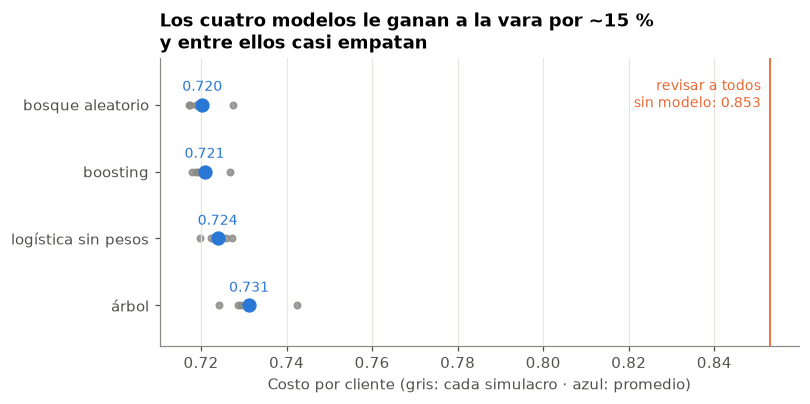

,ronda 1,ronda 2,ronda 3,ronda 4,ronda 5,costo,AUC,AP,prob. media,ahorro vs. vara
bosque aleatorio,0.7189,0.7171,0.7174,0.7206,0.7274,0.7203,0.7870,0.5593,0.2214,0.1556
boosting,0.7211,0.7189,0.7179,0.7194,0.7269,0.7208,0.7860,0.5614,0.2209,0.1550
logística sin pesos,0.7243,0.7222,0.7258,0.7199,0.7273,0.7239,0.7805,0.5490,0.2212,0.1514
árbol,0.7315,0.7241,0.7287,0.7293,0.7425,0.7312,0.7720,0.5385,0.2211,0.1428


In [10]:
finalistas = ["logística sin pesos", "árbol", "bosque aleatorio", "boosting"]
comp = tabla(finalistas).sort_values("costo")
rondas_cols = [c for c in comp.columns if c.startswith("ronda")]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for i, (nombre, fila) in enumerate(comp.iloc[::-1].iterrows()):
    ax.scatter(fila[rondas_cols], [i] * 5, color=GRIS, s=18, alpha=0.8)      # los cinco simulacros
    ax.scatter([fila["costo"]], [i], color=AZUL, s=70, zorder=3)              # su promedio
    ax.annotate(f"{fila['costo']:.3f}", (fila["costo"], i), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=AZUL)
ax.axvline(VARA, color=NARANJA, lw=1.2)
ax.annotate(f"revisar a todos\nsin modelo: {VARA:.3f}", (VARA, len(comp) - 0.6), xytext=(-6, 0),
            textcoords="offset points", ha="right", va="top", fontsize=9, color=NARANJA)
ax.set_yticks(range(len(comp)), comp.index[::-1])
ax.set_ylim(-0.6, len(comp) - 0.3)
ax.set_xlabel("Costo por cliente (gris: cada simulacro · azul: promedio)")
ax.set_title("Los cuatro modelos le ganan a la vara por ~15 %\ny entre ellos casi empatan")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
guardar(fig, "f11_comparacion_modelos")
plt.show()

comp["ahorro vs. vara"] = 1 - comp["costo"] / VARA
comp

In [11]:
# ¿La diferencia entre el mejor ensamble y la logística es real o es ruido de la partición?
# Se comparan ronda por ronda (mismos clientes en cada ronda).
dif = (tabla(["logística sin pesos"])[rondas_cols].iloc[0] - tabla(["boosting"])[rondas_cols].iloc[0])
print("Logística menos boosting, ronda por ronda:", dif.round(4).tolist())
print(f"Promedio: {dif.mean():.4f}  ·  boosting gana en {(dif > 0).sum()} de 5 rondas")
print(f"Eso es {100 * dif.mean() / resultados['logística sin pesos']['costo']:.1f} % del costo de la logística")

Logística menos boosting, ronda por ronda: [0.0032, 0.0034, 0.0079, 0.0005, 0.0004]
Promedio: 0.0031  ·  boosting gana en 5 de 5 rondas
Eso es 0.4 % del costo de la logística


**Lectura.**

- **Los cuatro le ganan a la vara** (0.853) por 14 % a 16 %. Tener modelo sí le sirve al banco.
- **Bosque (0.720) y boosting (0.721) empatan** en primer lugar. La logística queda en 0.724.
- La diferencia entre boosting y logística es de **0.003 por cliente, 0.4 % del costo**. Es pequeña
  pero no es puro ruido: el boosting gana en las 5 rondas.
- El árbol solo queda último y es el más inestable.

**Decisión: se elige la logística.** Razones:

1. **Casi empata, y en empate gana la más simple.** Se renuncia a 0.4 % de costo. Ese es el precio de
   la decisión y queda dicho.
2. **Se puede explicar.** Reducirle el límite a un cliente es una decisión que el banco tiene que
   poder justificar. La logística es una suma con pesos: se puede decir qué columnas subieron el
   riesgo de ese cliente. Un bosque de 300 árboles no.
3. **Ya dice la verdad.** Los umbrales necesitan probabilidades calibradas y la logística sin pesos
   las da sin un paso extra (sección 4).
4. **Es estable**: no depende de `C` (sección 3) y sus cinco rondas van de 0.720 a 0.727.

Que un modelo lineal casi empate con los ensambles también dice algo de los datos: la señal fuerte
(el historial de pagos) es simple, y con `PAY_*` como categoría la logística ya la captura.

## 8. Con y sin sexo y estado civil

`SEX` y `MARRIAGE` son atributos protegidos: reducirle el límite a alguien por ser hombre o por estar
soltero es discutible legal y éticamente. El EDA mostró que separan poco (hombres ~24 % contra mujeres
~21 %). La decisión que quedó escrita fue: **entrenar con y sin ellas, y si el costo casi no cambia,
quedarse sin ellas.** Se prueba en los dos modelos más distintos.

In [12]:
simular("logística sin SEX ni MARRIAGE", modelado.logistica(SIN_PROTEGIDAS, **logit_C), SIN_PROTEGIDAS)
simular("boosting sin SEX ni MARRIAGE", modelado.boosting(**busqueda_boosting.best_params_), SIN_PROTEGIDAS)

t = tabla(["logística sin pesos", "logística sin SEX ni MARRIAGE", "boosting", "boosting sin SEX ni MARRIAGE"])
print(f"Logística: quitar SEX y MARRIAGE cambia el costo en "
      f"{t.loc['logística sin SEX ni MARRIAGE', 'costo'] - t.loc['logística sin pesos', 'costo']:+.4f}")
print(f"Boosting:  quitar SEX y MARRIAGE cambia el costo en "
      f"{t.loc['boosting sin SEX ni MARRIAGE', 'costo'] - t.loc['boosting', 'costo']:+.4f}")
t

Logística: quitar SEX y MARRIAGE cambia el costo en +0.0015
Boosting:  quitar SEX y MARRIAGE cambia el costo en +0.0011


,ronda 1,ronda 2,ronda 3,ronda 4,ronda 5,costo,AUC,AP,prob. media
logística sin pesos,0.7243,0.7222,0.7258,0.7199,0.7273,0.7239,0.7805,0.5490,0.2212
logística sin SEX ni MARRIAGE,0.7280,0.7247,0.7275,0.7198,0.7267,0.7254,0.7800,0.5492,0.2212
boosting,0.7211,0.7189,0.7179,0.7194,0.7269,0.7208,0.7860,0.5614,0.2209
boosting sin SEX ni MARRIAGE,0.7226,0.7172,0.7219,0.7215,0.7261,0.7219,0.7858,0.5616,0.2211


**Lectura.** Quitar las dos columnas sube el costo 0.0015 en la logística y 0.0011 en el boosting:
**0.2 %**, menos de lo que se mueve el costo de una ronda a otra. Ordenan igual (AUC 0.780 en ambos
casos para la logística).

**Decisión.** **El modelo queda sin `SEX` ni `MARRIAGE`.** No se quitan "porque no importan" a secas:
se quitan porque usarlas tiene un costo ético y legal real, y lo que aportan es prácticamente cero.
Las columnas se conservan en los datos para revisar, en la evaluación, si el modelo se equivoca
distinto con hombres y mujeres.

`AGE` y `EDUCATION` se dejan en el modelo. Es una decisión discutible (la edad también es un atributo
sensible) y queda declarada como límite.

## 9. Modelo elegido

Con las columnas definitivas (sin `SEX` ni `MARRIAGE`) se vuelve a elegir `C` con los cinco
simulacros, para no arrastrar una perilla elegida con otras columnas.

In [13]:
busqueda_final = GridSearchCV(modelado.logistica(SIN_PROTEGIDAS), perillas_C, cv=cv,
                              scoring=modelado.PUNTAJE_COSTO, n_jobs=-1).fit(X[SIN_PROTEGIDAS], y)
C_FINAL = busqueda_final.best_params_["logisticregression__C"]
print((-pd.Series(busqueda_final.cv_results_["mean_test_score"], index=perillas_C["logisticregression__C"],
                  name="costo")).rename_axis("C").round(4).to_string())
print("\nC elegido:", C_FINAL)

# El notebook 03 arma el modelo con modelado.modelo_final(): aquí se comprueba que sea este mismo.
assert C_FINAL == modelado.C_FINAL, "Actualizar C_FINAL en src/modelado.py"
assert modelado.columnas_finales(X) == SIN_PROTEGIDAS

p_final = simular("MODELO ELEGIDO", modelado.modelo_final(X), SIN_PROTEGIDAS)
tabla(["MODELO ELEGIDO"])

C
0.0010    0.7326
0.0100    0.7257
0.0300    0.7254
0.1000    0.7263
1.0000    0.7265
10.0000   0.7264

C elegido: 0.03


,ronda 1,ronda 2,ronda 3,ronda 4,ronda 5,costo,AUC,AP,prob. media
MODELO ELEGIDO,0.7280,0.7247,0.7275,0.7198,0.7267,0.7254,0.7800,0.5492,0.2212


### 9.1 ¿Los umbrales teóricos sirven con este modelo?

Si el modelo dice la verdad, 0.12 y 0.35 deben ser (casi) los mejores umbrales también en la
práctica. Se comprueba buscando en una rejilla los dos umbrales que dan el menor costo sobre las
probabilidades de los simulacros.

In [14]:
rejilla_t = np.round(np.arange(0.04, 0.61, 0.01), 2)
costo_t = pd.DataFrame([(a, b, costos.costo_politica(y, p_final, a, b))
                        for a in rejilla_t for b in rejilla_t if a < b], columns=["t1", "t2", "costo"])
mejor_t = costo_t.loc[costo_t["costo"].idxmin()]
costo_teorico = costos.costo_politica(y, p_final, t1, t2)
print(f"Umbrales teóricos   t1 = {t1:.2f}, t2 = {t2:.2f}: costo {costo_teorico:.4f}")
print(f"Mejores en rejilla  t1 = {mejor_t.t1:.2f}, t2 = {mejor_t.t2:.2f}: costo {mejor_t.costo:.4f}")
print(f"Diferencia: {costo_teorico - mejor_t.costo:.4f}")

Umbrales teóricos   t1 = 0.12, t2 = 0.35: costo 0.7254
Mejores en rejilla  t1 = 0.12, t2 = 0.30: costo 0.7244
Diferencia: 0.0010


### 9.2 Qué decide el modelo (todavía en simulacros, no en la prueba)

La matriz de confusión de nuestro problema es de 3 × 2: la acción que se tomó contra lo que pasó.

In [15]:
decisiones = costos.tabla_decisiones(y, p_final, t1, t2)
decisiones["total"] = decisiones.sum(axis=1)
decisiones["% de clientes"] = 100 * decisiones["total"] / len(y)
decisiones["tasa de impago"] = decisiones["Impaga (1)"] / decisiones["total"]
display(decisiones)

# Precisión y recall sobre la clase de impago, para las dos alertas posibles.
impagos = int(y.sum())
for nombre, alerta in [("Revisar o reducir (p ≥ 0.12)", p_final >= t1), ("Reducir (p ≥ 0.35)", p_final >= t2)]:
    atrapados = int((alerta & (y == 1)).sum())
    print(f"{nombre:30s} alertas: {int(alerta.sum()):6,}   precisión: {atrapados / alerta.sum():.2f}   "
          f"recall: {atrapados / impagos:.2f}")

Realidad,Paga (0),Impaga (1),total,% de clientes,tasa de impago
Acción,,,,,
Mantener,8348,687,9035,37.6458,0.0760
Revisar,8582,2081,10663,44.4292,0.1952
Reducir,1761,2541,4302,17.9250,0.5907


Revisar o reducir (p ≥ 0.12)   alertas: 14,965   precisión: 0.31   recall: 0.87
Reducir (p ≥ 0.35)             alertas:  4,302   precisión: 0.59   recall: 0.48


**Lectura (simulacros).**

- **Los umbrales teóricos sirven.** Buscando en la rejilla se llega a 0.12 y 0.30 con una mejora de
  0.001. Se dejan 0.12 y 0.35: salen de los costos, no de mirar los datos, y la ganancia de moverlos
  es despreciable.
- **Mantener (38 % de los clientes):** impaga el 7.6 %. Aquí se escapan 687 impagos, el 13 % del total.
- **Reducir (18 %):** impaga el 59 %. A 1,761 clientes que sí iban a pagar se les reduciría el límite:
  es el error que más le duele al cliente.
- **Revisar (44 %):** impaga el 19.5 %, casi la tasa general. **Este es el punto débil.** El modelo
  manda a casi la mitad de los clientes a un analista, y en ese grupo no separa mucho mejor que el
  promedio. Con 24,000 clientes son más de 10,000 revisiones: el banco necesita esa capacidad o hay
  que subir `t1`. Se trata en el plan de despliegue.
- Como alerta amplia (revisar o reducir) el modelo atrapa al **87 %** de los impagos con precisión
  0.31. Como alerta fuerte (reducir) atrapa al 48 % con precisión 0.59.

## 10. Qué queda para la evaluación (notebook 03)

**Queda fijo y no se vuelve a tocar:**

- Modelo: `modelado.modelo_final(X)` (logística regularizada, `PAY_*` como categoría, cuatro
  variables candidatas, sin `SEX` ni `MARRIAGE`, sin pesos por clase).
- Umbrales: 0.12 y 0.35.
- Métrica: costo promedio por cliente, contra la vara de revisar a todos.

**Lo que hace el notebook 03:** entrena ese modelo con los 24,000 clientes, abre `test.csv` **una
vez**, reporta el costo, la matriz de 3 acciones, precisión y recall, y busca dónde falla y con quién
(edad, sexo, educación, cuentas inactivas).

## 11. Lo que esta fase no puede concluir

- Todos los números de este notebook son de **simulacros dentro del entrenamiento**. El número que
  se reporta es el de la prueba: 0.740 por cliente en el notebook 03, contra 0.725 de estos simulacros.
- El "costo" está en unidades de nuestros supuestos (5, 1, 0.3, 50 %, 30 %). Si el banco tuviera
  otros costos, cambian los umbrales y puede cambiar qué modelo conviene.
- Que la logística casi empate con el boosting vale para **estas columnas y estos clientes**. No dice
  que un modelo simple baste en otro banco.
- Los pesos de la logística dicen qué se **asocia** con el impago, no qué lo **causa**.
- Quitar `SEX` y `MARRIAGE` del modelo no garantiza que trate igual a todos los grupos: otras
  columnas pueden cargar esa información. Eso se revisa en la evaluación, por grupo.